# PathSnap: Step 1, Data Processing (Kaggle)

Runs the full data-processing step for both partitions:

1. Finds the dataset and checks that all 80 train and 10 student-test trips have their four files.
2. Audits every trip: GPS counts, timestamps and gaps, coordinate sanity, road-graph connectivity, candidate miss rate.
3. Builds the candidate feature table that the models and the HMM will use.
4. Runs interface and leakage checks, then saves CSV outputs to `/kaggle/working`.

**Before running:** attach the PathSnap data with *Add data*. It must contain either the `train/` and `student_test/` folders, or `Student_folder.zip`.

**Rules built into the code:** prediction uses only `.track`, `.nodes` and `.arcs`. The `.route` file is used only to create labels for training and scoring.

**Labels are a proxy.** Each GPS point is labelled with the nearest reference-route arc within 50 m. This is not the final route-aligned label, so report accuracy from it as a proxy.

In [11]:
import os, glob, json, time
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

def find_root():
    env = os.environ.get("PATHSNAP_ROOT")
    if env and os.path.isdir(os.path.join(env, "train")):
        return env
    def search():
        hits = glob.glob("/kaggle/input/**/train", recursive=True) + glob.glob("/kaggle/working/raw/**/train", recursive=True)
        for h in hits:
            parent = os.path.dirname(h)
            if os.path.isdir(h) and os.path.isdir(os.path.join(parent, "student_test")):
                return parent
        return None
    root = search()
    if root is None:
        zips = glob.glob("/kaggle/input/**/*.zip", recursive=True)
        if zips:
            import zipfile
            zipfile.ZipFile(zips[0]).extractall("/kaggle/working/raw")
            root = search()
    if root is None:
        raise FileNotFoundError("Attach the PathSnap data: a folder with train/ and student_test/, or Student_folder.zip")
    return root

ROOT = find_root()
OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs"
os.makedirs(OUT, exist_ok=True)
print("ROOT:", ROOT)
print("OUT :", OUT)

ROOT: /kaggle/input/datasets/juhishahh/pathsnap-student-data/Student folder
OUT : /kaggle/working


In [12]:
R_CAND = 50.0    # metres: candidate radius and label radius
K_CAND = 40      # nearest arc midpoints examined per GPS point
FEATS = ["dist", "hd", "alen", "speed", "dt"]

def load_trip(folder, tid, with_route=False):
    d = os.path.join(folder, tid)
    track = np.loadtxt(os.path.join(d, tid + ".track"), ndmin=2)
    nodes = np.loadtxt(os.path.join(d, tid + ".nodes"), ndmin=2)
    arcs = np.loadtxt(os.path.join(d, tid + ".arcs"), dtype=int, ndmin=2)
    route = None
    if with_route:
        route = np.loadtxt(os.path.join(d, tid + ".route"), dtype=int, ndmin=1)
    return track, nodes, arcs, route

def project(lon, lat, lat0):
    # local equirectangular projection in metres (city scale)
    return lon * np.cos(np.radians(lat0)) * 111320.0, lat * 110574.0

def seg_dist(px, py, ax, ay, bx, by):
    abx, aby = bx - ax, by - ay
    t = np.clip(((px - ax) * abx + (py - ay) * aby) / (abx ** 2 + aby ** 2 + 1e-9), 0, 1)
    return np.hypot(px - (ax + t * abx), py - (ay + t * aby))

def connectivity(nodes, arcs):
    n = len(nodes)
    valid = (arcs[:, 0] >= 0) & (arcs[:, 0] < n) & (arcs[:, 1] >= 0) & (arcs[:, 1] < n)
    a = arcs[valid]
    g = coo_matrix((np.ones(len(a)), (a[:, 0], a[:, 1])), shape=(n, n))
    ncomp, _ = connected_components(g, directed=True, connection="weak")
    return ncomp

def candidates(track, nodes, arcs):
    """Candidate arcs per GPS observation. Does NOT use the reference route."""
    lat0 = track[:, 1].mean()
    nx, ny = project(nodes[:, 0], nodes[:, 1], lat0)
    s, e = arcs[:, 0], arcs[:, 1]
    ax, ay, bx, by = nx[s], ny[s], nx[e], ny[e]
    mx, my = (ax + bx) / 2, (ay + by) / 2
    alen = np.hypot(bx - ax, by - ay)
    abear = np.arctan2(bx - ax, by - ay)
    px, py = project(track[:, 0], track[:, 1], lat0)
    n = len(px)
    dx = np.r_[np.diff(px), 0.0]
    dy = np.r_[np.diff(py), 0.0]
    dt = np.r_[np.diff(track[:, 2]), 1.0]
    dt = np.where(dt <= 0, 1.0, dt)
    speed = np.hypot(dx, dy) / dt
    heading = np.arctan2(dx, dy)
    k = min(K_CAND, len(arcs))
    _, idx = cKDTree(np.column_stack([mx, my])).query(np.column_stack([px, py]), k=k)
    idx = np.asarray(idx).reshape(n, k)
    obs = np.repeat(np.arange(n), k)
    arc = idx.ravel()
    d = seg_dist(px[obs], py[obs], ax[arc], ay[arc], bx[arc], by[arc])
    hd = np.abs(np.angle(np.exp(1j * (heading[obs] - abear[arc]))))
    keep = d <= R_CAND
    return pd.DataFrame({
        "obs": obs[keep], "arc": arc[keep], "dist": d[keep], "hd": hd[keep],
        "alen": alen[arc[keep]], "speed": speed[obs[keep]], "dt": dt[obs[keep]],
    })

def reference_labels(track, nodes, arcs, route):
    """TRAINING AND SCORING ONLY. Nearest reference-route arc per GPS point (proxy label)."""
    lat0 = track[:, 1].mean()
    nx, ny = project(nodes[:, 0], nodes[:, 1], lat0)
    s, e = arcs[:, 0], arcs[:, 1]
    px, py = project(track[:, 0], track[:, 1], lat0)
    best = np.full(len(px), np.inf)
    lab = np.full(len(px), -1)
    for a in np.unique(route):
        d = seg_dist(px, py, nx[s[a]], ny[s[a]], nx[e[a]], ny[e[a]])
        m = d < best
        best[m] = d[m]
        lab[m] = a
    lab[best > R_CAND] = -1
    return lab

def trip_frames(folder, tid, with_route=False):
    track, nodes, arcs, route = load_trip(folder, tid, with_route)
    cand = candidates(track, nodes, arcs)
    cand.insert(0, "trip", tid)
    obs = pd.DataFrame({"trip": tid, "obs": np.arange(len(track)),
                        "lon": track[:, 0], "lat": track[:, 1], "t": track[:, 2]})
    if with_route:
        obs["label"] = reference_labels(track, nodes, arcs, route)
        cand = cand.merge(obs[["obs", "label"]], on="obs")
        cand["y"] = ((cand["arc"] == cand["label"]) & (cand["label"] >= 0)).astype(int)
    return cand, obs

In [13]:
EXT = ["track", "nodes", "arcs", "route"]

def trips_in(part):
    base = os.path.join(ROOT, part)
    return sorted(d for d in os.listdir(base) if os.path.isdir(os.path.join(base, d)))

inv_rows = []
for part in ["train", "student_test"]:
    for tid in trips_in(part):
        missing = [x for x in EXT if not os.path.isfile(os.path.join(ROOT, part, tid, f"{tid}.{x}"))]
        inv_rows.append({"partition": part, "trip": tid, "missing": ",".join(missing)})
inv = pd.DataFrame(inv_rows)
print(inv.groupby("partition").agg(trips=("trip", "count"),
                                   trips_with_missing_files=("missing", lambda s: int((s != "").sum()))))

train_trips, test_trips = set(trips_in("train")), set(trips_in("student_test"))
print("trip IDs shared between partitions:", len(train_trips & test_trips))
assert (inv["missing"] == "").all(), "some trips are missing files"
assert len(train_trips) == 80 and len(test_trips) == 10, "expected 80 train and 10 student-test trips"
print("inventory OK")

              trips  trips_with_missing_files
partition                                    
student_test     10                         0
train            80                         0
trip IDs shared between partitions: 0
inventory OK


In [21]:
def audit_trip(part, tid):
    track, nodes, arcs, route = load_trip(os.path.join(ROOT, part), tid, with_route=True)
    N = len(track)
    dt = np.diff(track[:, 2])
    ncomp = connectivity(nodes, arcs)
    cand = candidates(track, nodes, arcs)
    lab = reference_labels(track, nodes, arcs, route)
    labelled = lab >= 0
    hit = cand["arc"].values == lab[cand["obs"].values]
    hit_flag = np.zeros(N, dtype=bool)
    hit_flag[cand["obs"].values[hit]] = True
    cands_per_obs = np.bincount(cand["obs"].values, minlength=N)
    n_lab = int(labelled.sum())
    return {
        "partition": part, "trip": tid,
        "gps_rows": N, "route_arcs": len(route),
        "nodes": len(nodes), "arcs": len(arcs), "weak_components": ncomp,
        "nan_values": int(np.isnan(track).sum()),
        "bad_lat_lon": int(((np.abs(track[:, 1]) > 90) | (np.abs(track[:, 0]) > 180)).sum()),
        "median_dt_s": float(np.median(dt)) if len(dt) else None,
        "pct_1s_steps": round(100 * float((dt == 1).mean()), 2) if len(dt) else None,
        "max_gap_s": float(dt.max()) if len(dt) else None,
        "non_increasing_time": int((dt <= 0).sum()),
        "obs_no_candidate": int((cands_per_obs == 0).sum()),
        "mean_candidates_per_obs": round(float(cands_per_obs.mean()), 2),
        "labelled_frac": round(n_lab / N, 3),
        "candidate_miss_rate": round(float(1 - hit_flag[labelled].mean()), 4) if n_lab else None,
        "route_ids_out_of_range": int((route >= len(arcs)).sum()),
        "arc_refs_out_of_range": int(((arcs < 0) | (arcs >= len(nodes))).sum()),
    }

t0 = time.time()
rows = []
for part in ["train", "student_test"]:
    for tid in trips_in(part):
        rows.append(audit_trip(part, tid))
audit = pd.DataFrame(rows)
audit.to_csv(os.path.join(OUT, "dataset_audit_per_trip.csv"), index=False)
print(f"audited {len(audit)} trips in {time.time() - t0:.1f}s")

audited 90 trips in 11.4s


In [15]:
summary = audit.groupby("partition").agg(
    trips=("trip", "count"),
    gps_rows_median=("gps_rows", "median"),
    gps_rows_max=("gps_rows", "max"),
    route_arcs_median=("route_arcs", "median"),
    nodes_median=("nodes", "median"),
    arcs_median=("arcs", "median"),
    pct_1s_steps_mean=("pct_1s_steps", "mean"),
    max_gap_s=("max_gap_s", "max"),
    candidate_miss_rate_mean=("candidate_miss_rate", "mean"),
    obs_no_candidate_total=("obs_no_candidate", "sum"),
    nan_total=("nan_values", "sum"),
    bad_coords_total=("bad_lat_lon", "sum"),
    non_increasing_time_total=("non_increasing_time", "sum"),
    arc_refs_bad_total=("arc_refs_out_of_range", "sum"),
    route_bad_total=("route_ids_out_of_range", "sum"),
).T
summary.to_csv(os.path.join(OUT, "dataset_audit_summary.csv"))
print(summary.to_string())

partition                  student_test          train
trips                          10.00000      80.000000
gps_rows_median              1420.00000    1529.000000
gps_rows_max                 3958.00000   19313.000000
route_arcs_median             250.00000     280.000000
nodes_median                 6596.50000    9608.000000
arcs_median                 13145.00000   19526.500000
pct_1s_steps_mean              98.19900      93.829625
max_gap_s                     210.00000  153064.000000
candidate_miss_rate_mean        0.01495       0.018166
obs_no_candidate_total         67.00000   18874.000000
nan_total                       0.00000       0.000000
bad_coords_total                0.00000       0.000000
non_increasing_time_total       0.00000       0.000000
arc_refs_bad_total              0.00000       0.000000
route_bad_total                 0.00000       0.000000


In [16]:
def build_feature_table(part):
    cs, os_ = [], []
    for tid in trips_in(part):
        c, o = trip_frames(os.path.join(ROOT, part), tid, with_route=True)
        cs.append(c)
        os_.append(o)
    return pd.concat(cs, ignore_index=True), pd.concat(os_, ignore_index=True)

Ctr, Otr = build_feature_table("train")
Cte, Ote = build_feature_table("student_test")
Ctr.to_csv(os.path.join(OUT, "features_train.csv.gz"), index=False, compression="gzip")
Cte.to_csv(os.path.join(OUT, "features_student_test.csv.gz"), index=False, compression="gzip")
Otr.to_csv(os.path.join(OUT, "observations_train.csv.gz"), index=False, compression="gzip")
Ote.to_csv(os.path.join(OUT, "observations_student_test.csv.gz"), index=False, compression="gzip")
print("train: candidates", len(Ctr), "observations", len(Otr))
print("student_test: candidates", len(Cte), "observations", len(Ote))

train: candidates 1796686 observations 208417
student_test: candidates 202711 observations 19160


In [17]:
audit_arcs = dict(zip(audit["trip"], audit["arcs"]))
audit_gps = dict(zip(audit["trip"], audit["gps_rows"]))

def check_partition(C, O, name):
    assert C["y"].isin([0, 1]).all(), "y must be 0 or 1"
    assert not ((C["y"] == 1) & (C["arc"] != C["label"])).any(), "positive label does not match arc"
    assert not O.duplicated(["trip", "obs"]).any(), "duplicate observation keys"
    n_arcs = C["trip"].map(audit_arcs)
    assert ((C["arc"] >= 0) & (C["arc"] < n_arcs)).all(), "arc id out of range for its own trip"
    counts = O.groupby("trip").size()
    assert all(counts[t] == audit_gps[t] for t in counts.index), "observation count differs from audit"
    print(f"{name}: checks passed | trips={O['trip'].nunique()} observations={len(O)} candidates={len(C)}")

check_partition(Ctr, Otr, "train")
check_partition(Cte, Ote, "student_test")
print("All interface checks passed. Arc IDs are kept per trip; no trip ID overlaps between partitions.")

train: checks passed | trips=80 observations=208417 candidates=1796686
student_test: checks passed | trips=10 observations=19160 candidates=202711
All interface checks passed. Arc IDs are kept per trip; no trip ID overlaps between partitions.


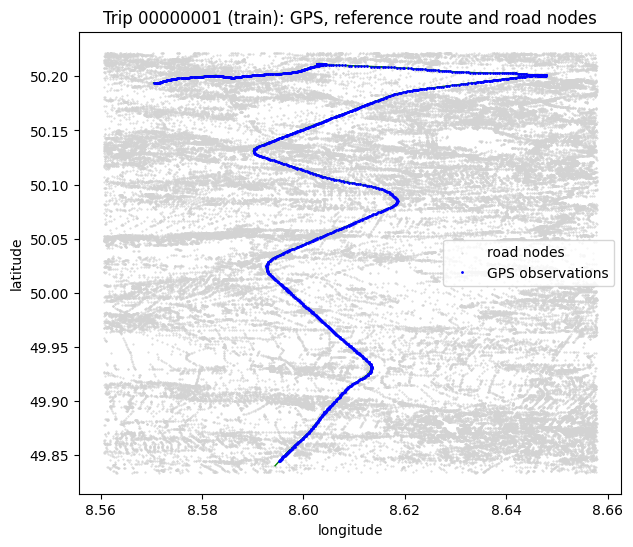

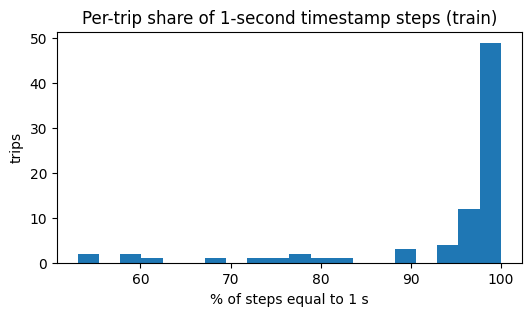

In [18]:
try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None
    print("matplotlib not available; plots skipped")

tid = trips_in("train")[0]
track, nodes, arcs, route = load_trip(os.path.join(ROOT, "train"), tid, with_route=True)
if plt is not None:
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.scatter(nodes[:, 0], nodes[:, 1], s=0.2, c="lightgray", label="road nodes")
    for a in np.unique(route):
        ax.plot([nodes[arcs[a, 0], 0], nodes[arcs[a, 1], 0]],
                [nodes[arcs[a, 0], 1], nodes[arcs[a, 1], 1]], "g-", lw=1)
    ax.plot(track[:, 0], track[:, 1], "b.", ms=2, label="GPS observations")
    ax.set_title(f"Trip {tid} (train): GPS, reference route and road nodes")
    ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.legend()
    plt.show()

    dts = audit.loc[audit.partition == "train", "pct_1s_steps"]
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.hist(dts.dropna(), bins=20)
    ax.set_title("Per-trip share of 1-second timestamp steps (train)")
    ax.set_xlabel("% of steps equal to 1 s"); ax.set_ylabel("trips")
    plt.show()

In [19]:
try:
    import folium
    m = folium.Map(location=[track[:, 1].mean(), track[:, 0].mean()], zoom_start=15)
    gps = folium.FeatureGroup(name="GPS observations (every 10th)").add_to(m)
    for lon, lat in track[::10, :2]:
        folium.CircleMarker([lat, lon], radius=2, color="blue").add_to(gps)
    ref = folium.FeatureGroup(name="Reference route").add_to(m)
    for a in np.unique(route):
        folium.PolyLine([[nodes[arcs[a, 0], 1], nodes[arcs[a, 0], 0]],
                         [nodes[arcs[a, 1], 1], nodes[arcs[a, 1], 0]]],
                        color="green", weight=4).add_to(ref)
    folium.LayerControl().add_to(m)
    path = os.path.join(OUT, f"map_{tid}.html")
    m.save(path)
    print("saved Folium map:", path)
except ImportError:
    print("folium not available; map skipped")

saved Folium map: /kaggle/working/map_00000001.html


In [20]:
print("Files written to", OUT)
for f in sorted(os.listdir(OUT)):
    p = os.path.join(OUT, f)
    if os.path.isfile(p):
        print(f"  {f:40s} {os.path.getsize(p) / 1e6:8.2f} MB")

Files written to /kaggle/working
  dataset_audit_per_trip.csv                   0.01 MB
  dataset_audit_summary.csv                    0.00 MB
  features_student_test.csv.gz                 4.74 MB
  features_train.csv.gz                       42.24 MB
  map_00000001.html                            0.34 MB
  observations_student_test.csv.gz             0.22 MB
  observations_train.csv.gz                    2.35 MB
